# Experiment 1: PD outcomes and evaluation

When does continued pretraining (CPT) on credit tables improve a tabular foundation model on credit tables it never saw during CPT, when does it change little, and when does it hurt? Every result below compares an adapted model with the original checkpoint of the same base on identical held-out tables and outer folds (primary quantity: AUC change in percentage points (pp); positive always means CPT is better). The notebook moves from single-choice contrasts to the complete 4 × 2 × 2 recipe grid per base (peak learning rate × L2-SP strength × update scope), then to individual tables, probability or error quality, and non-credit retention. The grid is descriptive: an observed maximum is not an independently validated recipe, and section 3 quantifies how much selecting the best recipe would overstate.

## 0. Evidence and scope

Positive effects always mean improvement over the original model. A favourable contrast between two CPT choices can mean less damage; only a positive CPT-versus-original effect is a gain over the starting weights. The predefined reference recipe (all weights, LR 3e-7, L2-SP λ 0.003) was fixed before results were seen, following Real-TabPFN.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, publication as pub, diagnostics as dg
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
from src.data.dataset_names import display_frame
style.apply()
sink = FigureSaver('experiment1/03_results_pd')
report = cp.NotebookReport('Experiment 1: PD outcomes and evaluation', sink=sink)
TRACK = 'pd'
print(source_description())
report.add('0. Evidence and scope', source_description() + '\n' + 'Does stronger credit-domain adaptation improve transfer to excluded credit tables, and what does it preserve or lose on the non-credit panel? The grid is descriptive; the highest test score is not a selected deployment result.')

from src.visualize import dashboards as db, choice_effects as ce
from src.visualize import finishing as finish
from src.visualize import prediction_diagnostics as pred
from src.visualize import synthesis as sy


DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Evidence and benchmark eligibility

Each final comparison requires five finite, successful outer folds and paired original predictions. All recipes shown within one model use the same tables across the displayed metrics. Non-credit summaries additionally require all four CPT partitions.

In [2]:
run = cp.load_campaign(1, TRACK)
grid = ce.benchmark_grid(run)
effects = sy.table_effects(run, sy.PRIMARY[TRACK], experiment=1)
report.table('Available evidence', pub.availability(run))
report.add('1. Evidence and benchmark eligibility', cp.coverage_summary(run))

C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


,evidence,records,origin
0,Planned trials,256,Config; not scheduler state
1,Completed trials,256,DATA manifests
2,Epoch rows,201472,Project training diagnostics
3,Milestone rows,1536,Project trajectory diagnostics
4,Benchmark folds,11715,Project final evaluation


## 2. Which CPT choices help?

Compare L2-SP anchoring with no anchoring, a frozen transformer backbone with all parameters updated, and each larger learning rate with the lowest rate. Match every other setting before averaging within table, then weight tables equally. Keep model identities and metric scales separate; opposite effects must not cancel in a pooled model average.

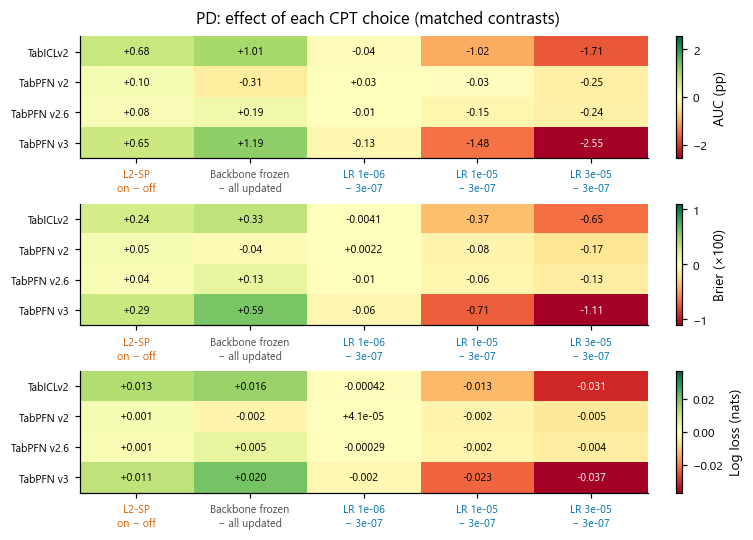

PD. Experiment 1, final five-fold benchmark on held-out credit tables. 17 complete tables per model. Each column changes one CPT choice: L2-SP anchoring on (λ = 0.003) minus off (λ = 0), frozen transformer backbone minus all parameters updated, or a larger peak learning rate minus the lowest (3e-7). Each cell pairs the same table and all other recipe settings, averages those matched differences within table, then weights tables equally; positive values favour the named alternative. Anchoring and scope contrasts average over all four learning rates; each rate contrast averages over both anchoring and scope settings. A favourable contrast can mean less deterioration rather than a gain over the original weights (see the recipe grid). Column labels are coloured by the parameter varied (learning rate blue, L2-SP orange, update scope grey). AUC contrasts are in percentage points and Brier contrasts are multiplied by 100; Brier and log-loss signs are reversed so that reductions are positive. Colours are symmetric about zero within each metric panel. These are descriptive contrasts over the fixed grid.

In [3]:
cp.show(sink, ce.plot_choices(grid, TRACK), track=TRACK)
report.add('2. Which CPT choices help?', 'The figure shows alternative minus reference, with the sign oriented toward improvement. Complete marginal effects at each choice level and every matched table contrast accompany it. These descriptive comparisons concern the observed fixed grid; recipe cells and folds are not independent replications.')

## 3. Every recipe against its original model

Average choice effects can hide interactions, and averages over tables can hide heterogeneity. The recipe grid shows every learning-rate × L2-SP × scope combination per base, with the number of tables that improved; peak learning rate is labelled in blue and L2-SP strength in orange throughout. The table maps show which tables carry each mean. The low-rate figure adds medians and table interquartile ranges, and the last figure places credit transfer against non-credit retention. The selection table contrasts the predefined reference with the observed best recipe and with a leave-one-table-out choice, which estimates how much picking the best recipe from this grid overstates its effect.

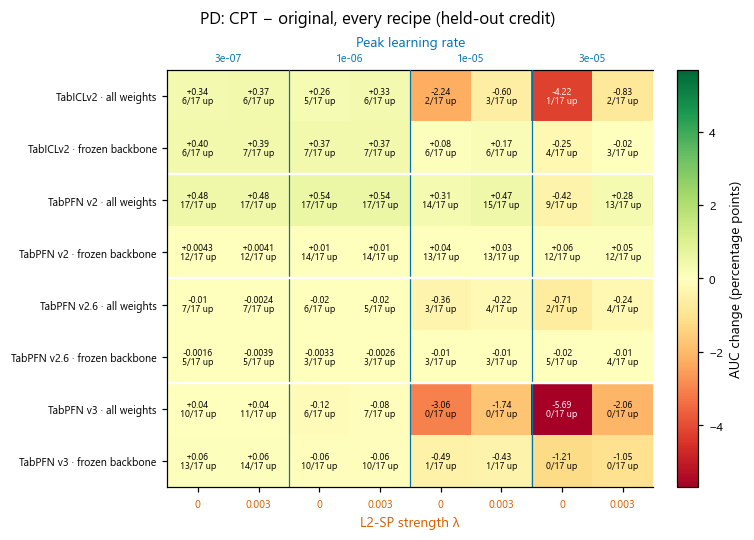

PD. Experiment 1, final five-fold benchmark on held-out credit tables: AUC change (percentage points), CPT minus the original model of the same base. 17 complete tables per model. Each cell is the equal-table mean effect of one recipe, with the number of tables whose effect exceeds 0 pp ("up") over the number of complete tables. Positive values favour CPT. Columns cross the four peak learning rates (top labels, blue) with L2-SP strength λ ∈ {0, 0.003} (bottom labels, orange); rows cross each base with the update scope (all trainable weights, or the dominant transformer stack frozen while embeddings and prediction components remain trainable). Every planned combination is shown on one common table cohort within each base. Colours share one symmetric scale; printed values retain small effects. Five outer folds are averaged within table before tables are weighted equally. The predefined reference recipe is full updates at LR 3e-7 and λ 0.003; any other cell with a higher value is an observed grid maximum, not an independently validated choice.

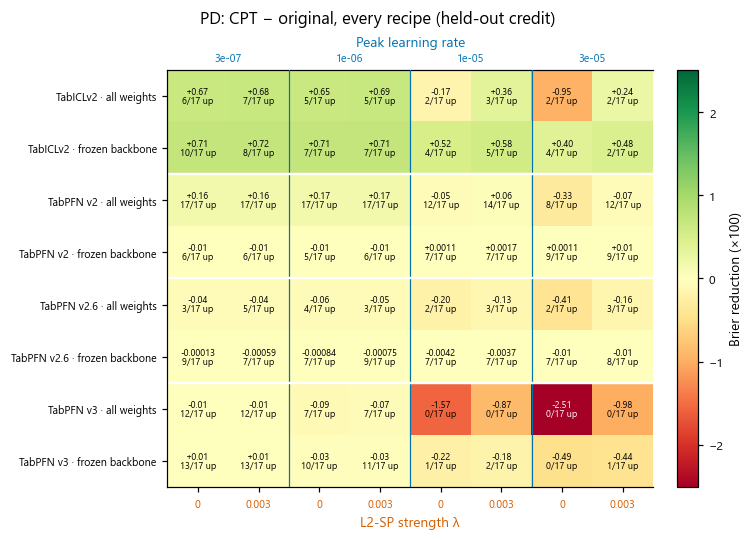

PD. Experiment 1, final five-fold benchmark on held-out credit tables: Brier reduction (×100), CPT minus the original model of the same base. 17 complete tables per model. Each cell is the equal-table mean effect of one recipe, with the number of tables whose effect exceeds 0 ("up") over the number of complete tables. Positive values favour CPT. Columns cross the four peak learning rates (top labels, blue) with L2-SP strength λ ∈ {0, 0.003} (bottom labels, orange); rows cross each base with the update scope (all trainable weights, or the dominant transformer stack frozen while embeddings and prediction components remain trainable). Every planned combination is shown on one common table cohort within each base. Colours share one symmetric scale; printed values retain small effects. Five outer folds are averaged within table before tables are weighted equally. The predefined reference recipe is full updates at LR 3e-7 and λ 0.003; any other cell with a higher value is an observed grid maximum, not an independently validated choice.

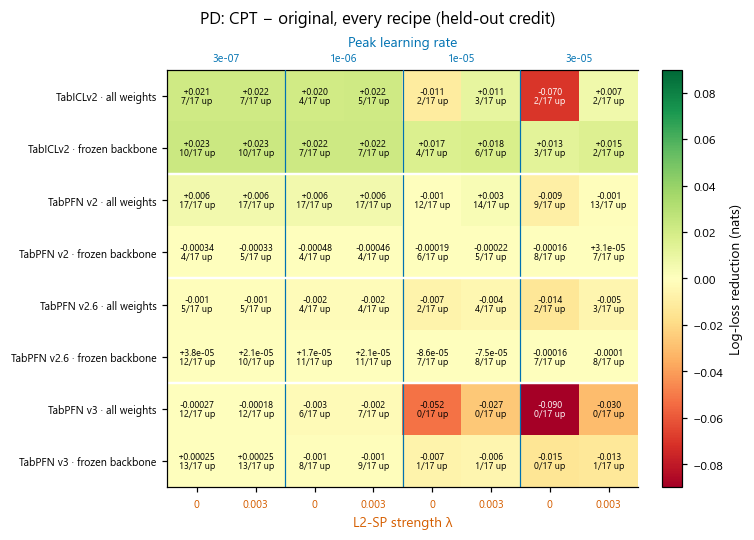

PD. Experiment 1, final five-fold benchmark on held-out credit tables: Log-loss reduction (nats), CPT minus the original model of the same base. 17 complete tables per model. Each cell is the equal-table mean effect of one recipe, with the number of tables whose effect exceeds 0 ("up") over the number of complete tables. Positive values favour CPT. Columns cross the four peak learning rates (top labels, blue) with L2-SP strength λ ∈ {0, 0.003} (bottom labels, orange); rows cross each base with the update scope (all trainable weights, or the dominant transformer stack frozen while embeddings and prediction components remain trainable). Every planned combination is shown on one common table cohort within each base. Colours share one symmetric scale; printed values retain small effects. Five outer folds are averaged within table before tables are weighted equally. The predefined reference recipe is full updates at LR 3e-7 and λ 0.003; any other cell with a higher value is an observed grid maximum, not an independently validated choice.

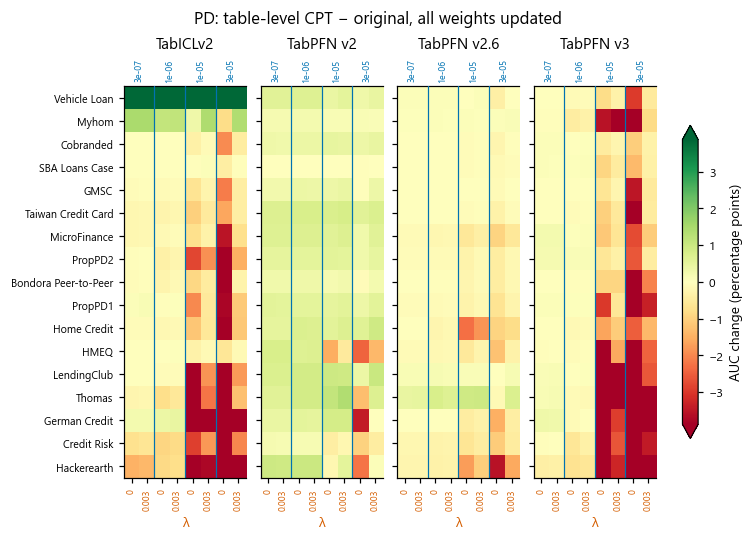

PD. Experiment 1, final five-fold benchmark: auc change (percentage points) of every held-out credit table (rows) for each recipe with all trainable weights updated, CPT minus the original model of the same base. Columns cross peak learning rate (upper labels, blue) with L2-SP strength λ (lower labels, orange). Rows are ordered by the table's mean effect over all recipes and bases, so tables that improve under many recipes are at the top. Five outer folds are averaged within table. Colours are symmetric about zero and saturate at the 95th percentile of |effect| (3.88); exact values are in the notebook summary.

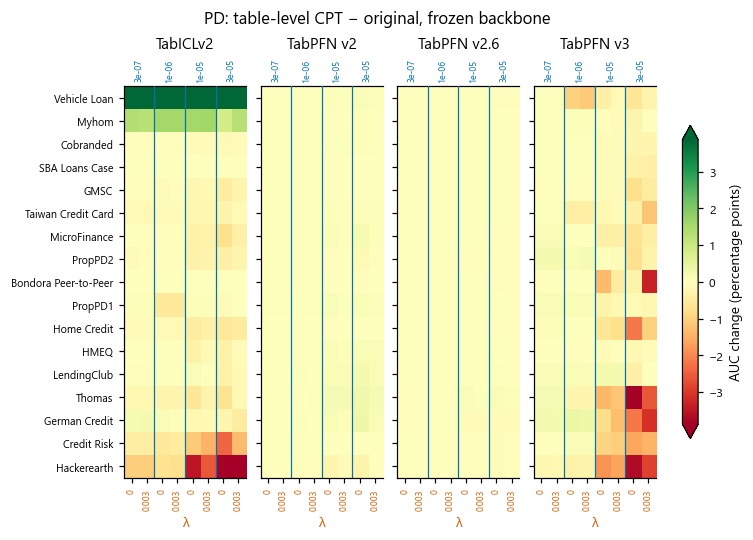

PD. Experiment 1, final five-fold benchmark: auc change (percentage points) of every held-out credit table (rows) for each recipe with the dominant transformer backbone frozen, CPT minus the original model of the same base. Columns cross peak learning rate (upper labels, blue) with L2-SP strength λ (lower labels, orange). Rows are ordered by the table's mean effect over all recipes and bases, so tables that improve under many recipes are at the top. Five outer folds are averaged within table. Colours are symmetric about zero and saturate at the 95th percentile of |effect| (3.88); exact values are in the notebook summary.

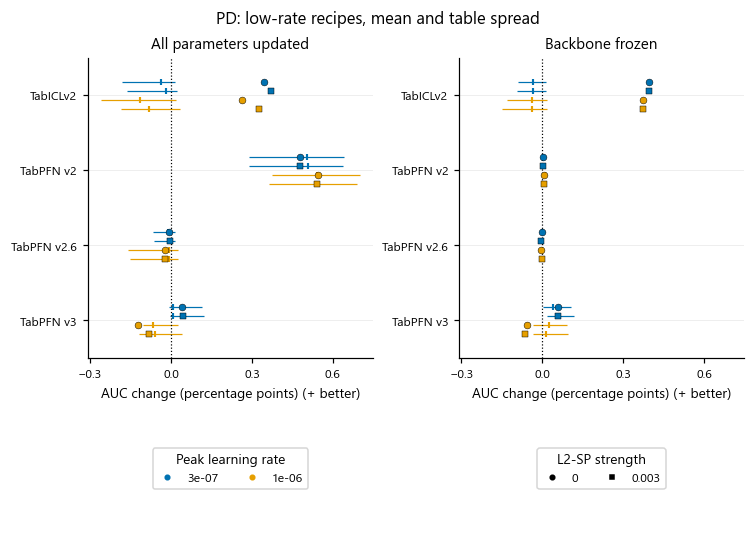

PD. Experiment 1, final five-fold benchmark on held-out credit tables, at the two lowest peak learning rates (3e-7 and 1e-6). All anchoring and update-scope combinations at these rates are shown; none is selected by its outcome. Values are auc change (percentage points), CPT minus the original model of the same base. Markers give the equal-table mean (colour: learning rate; circle λ = 0, square λ = 0.003), vertical ticks the median table and horizontal segments the table interquartile range (heterogeneity across tables, not a confidence interval). 17 complete tables per model. Five outer folds are averaged within table. Vertical offsets only separate settings. Both panels share one horizontal scale; positive values favour CPT. A mean far from its median indicates that a few tables drive the average.

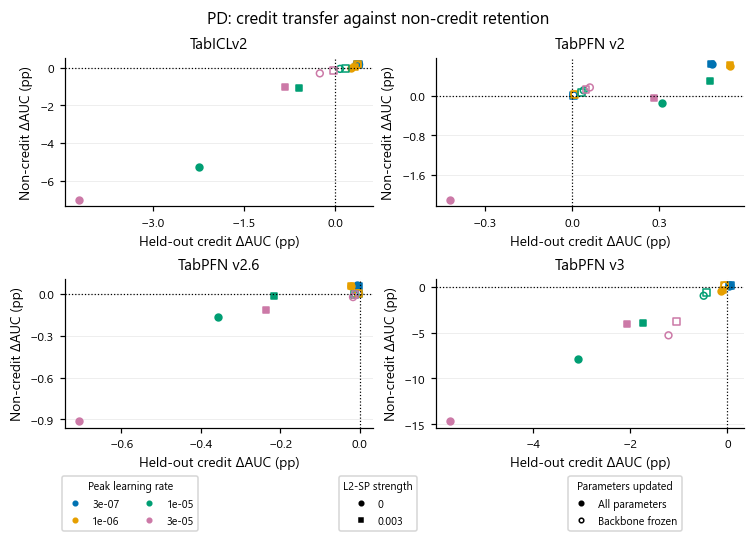

PD. Experiment 1, final five-fold benchmark: each mark is one of the 16 recipes, placed at its equal-table mean change on held-out credit tables (horizontal) and on the same-task non-credit retention panel (vertical), both relative to the original model of the same base. Credit: 17 complete tables per model. Non-credit: 4 complete tables per model. Colour encodes peak learning rate, circle/square L2-SP λ = 0/0.003, filled/open all-weights/frozen-backbone updates. The upper-right quadrant improves both domains; the lower-right gains on credit while losing on the retention panel. Non-credit effects first average all four CPT training partitions per table. Axis limits differ between models; coinciding recipes overlap. A four-table retention panel does not establish general retention.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabICLv2,roc_auc,17,0.791790,0.792613,0.000823,...,-0.003289,0.000433,-0.035055,0.068600,3,4,10,26,85,0.176471
1,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabPFN v2,roc_auc,17,0.778915,0.779312,0.000397,...,0.000011,0.000946,-0.002281,0.001725,4,12,1,55,85,0.235294
2,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabPFN v2.6,roc_auc,17,0.792242,0.792135,-0.000107,...,-0.000282,-0.000042,-0.000702,0.001103,1,16,0,21,85,0.058824
3,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0,TabPFN v3,roc_auc,17,0.798170,0.793301,-0.004868,...,-0.007981,-0.000676,-0.018535,0.002261,1,4,12,11,85,0.058824
4,1,Main grid,Frozen backbone,E1 frozen · LR 1e-05 · λ 0.003,TabICLv2,roc_auc,17,0.791790,0.793514,0.001724,...,-0.002495,0.000567,-0.025888,0.069409,2,5,10,30,85,0.117647
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,1,Main grid,Full CPT,E1 all · LR 3e-07 · λ 0,TabPFN v3,roc_auc,17,0.798170,0.798568,0.000398,...,-0.000076,0.001141,-0.003723,0.003186,5,11,1,52,85,0.294118
60,1,Main grid,Full CPT,E1 all · LR 3e-07 · λ 0.003,TabICLv2,roc_auc,17,0.791790,0.795485,0.003695,...,-0.001643,0.000222,-0.013719,0.071504,4,8,5,34,85,0.235294
61,1,Main grid,Full CPT,E1 all · LR 3e-07 · λ 0.003,TabPFN v2,roc_auc,17,0.778915,0.783687,0.004773,...,0.002890,0.006384,0.000037,0.009349,16,1,0,80,85,0.941176
62,1,Main grid,Full CPT,E1 all · LR 3e-07 · λ 0.003,TabPFN v2.6,roc_auc,17,0.792242,0.792218,-0.000024,...,-0.000629,0.000164,-0.002185,0.004683,2,13,2,30,85,0.117647


,base,tables,recipes,reference_recipe,reference_mean,best_observed_recipe,best_observed_mean,leave_one_table_out_mean,leave_one_table_out_improved,recipes_chosen
0,TabICLv2,17,16,E1 all · LR 3e-07 · λ 0.003,0.003695,E1 frozen · LR 3e-07 · λ 0,0.003964,0.003552,5,"E1 frozen · LR 3e-07 · λ 0 ×15, E1 frozen · LR..."
1,TabPFN v2,17,16,E1 all · LR 3e-07 · λ 0.003,0.004773,E1 all · LR 1e-06 · λ 0,0.005437,0.005437,17,E1 all · LR 1e-06 · λ 0 ×17
2,TabPFN v2.6,17,16,E1 all · LR 3e-07 · λ 0.003,-0.000024,E1 frozen · LR 3e-07 · λ 0,-0.000016,-0.000488,2,"E1 all · LR 3e-07 · λ 0.003 ×8, E1 frozen · LR..."
3,TabPFN v3,17,16,E1 all · LR 3e-07 · λ 0.003,0.000430,E1 frozen · LR 3e-07 · λ 0.003,0.000603,0.000603,14,E1 frozen · LR 3e-07 · λ 0.003 ×17


,base,learning_rate,l2sp_lambda,frozen,sampling,dataset,domain,metric,effect,partitions
3264,TabICLv2,3.000000e-07,0.000,False,one_sample,openml_46905,ood,roc_auc,-0.002284,4
3265,TabICLv2,3.000000e-07,0.000,False,one_sample,openml_46947,ood,roc_auc,-0.001244,4
3266,TabICLv2,3.000000e-07,0.000,False,one_sample,openml_46952,ood,roc_auc,-0.000213,4
3267,TabICLv2,3.000000e-07,0.000,False,one_sample,openml_46956,ood,roc_auc,0.010459,4
3268,TabICLv2,3.000000e-07,0.000,True,one_sample,openml_46905,ood,roc_auc,-0.001388,4
...,...,...,...,...,...,...,...,...,...,...
4027,TabPFN v3,3.000000e-05,0.003,False,one_sample,openml_46956,ood,log_loss,-0.022718,4
4028,TabPFN v3,3.000000e-05,0.003,True,one_sample,openml_46905,ood,log_loss,-0.032606,4
4029,TabPFN v3,3.000000e-05,0.003,True,one_sample,openml_46947,ood,log_loss,-0.001903,4
4030,TabPFN v3,3.000000e-05,0.003,True,one_sample,openml_46952,ood,log_loss,-0.023381,4


,domain,metric,base,learning_rate,l2sp_lambda,frozen,sampling,mean,median,q25,q75,tables,improved
0,credit,brier_score,TabICLv2,3.000000e-07,0.000,False,one_sample,0.006658,-0.000176,-0.000300,0.000093,17,6
1,credit,brier_score,TabICLv2,3.000000e-07,0.000,True,one_sample,0.007149,0.000012,-0.000122,0.000114,17,10
2,credit,brier_score,TabICLv2,3.000000e-07,0.003,False,one_sample,0.006803,-0.000083,-0.000249,0.000082,17,7
3,credit,brier_score,TabICLv2,3.000000e-07,0.003,True,one_sample,0.007164,-0.000002,-0.000108,0.000148,17,8
4,credit,brier_score,TabICLv2,1.000000e-06,0.000,False,one_sample,0.006536,-0.000394,-0.000713,0.000200,17,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
379,ood,roc_auc,TabPFN v3,1.000000e-05,0.003,True,one_sample,-0.006585,-0.002835,-0.009171,-0.000249,4,1
380,ood,roc_auc,TabPFN v3,3.000000e-05,0.000,False,one_sample,-0.146199,-0.126417,-0.182265,-0.090351,4,0
381,ood,roc_auc,TabPFN v3,3.000000e-05,0.000,True,one_sample,-0.052973,-0.042764,-0.087460,-0.008276,4,0
382,ood,roc_auc,TabPFN v3,3.000000e-05,0.003,False,one_sample,-0.040499,-0.040627,-0.064353,-0.016773,4,0


In [4]:
for metric in ('roc_auc', 'brier_score', 'log_loss'):
    cp.show(sink, ce.plot_combinations(grid, TRACK, metric), track=TRACK)
cp.show(sink, ce.plot_table_recipes(grid, TRACK, 'roc_auc'), track=TRACK)
cp.show(sink, ce.plot_conservative_recipes(grid, TRACK, 'roc_auc'), track=TRACK)
cp.show(sink, ce.plot_transfer_retention(grid, TRACK), track=TRACK)
report.table('Every recipe: original and adapted scores, paired change and table/fold consistency', sy.summarize(effects))
report.table('Predefined reference, observed best recipe and leave-one-table-out selection', sy.selection_check(effects))
report.table('Non-credit effects for every complete recipe and metric', grid[grid.domain.eq('ood')] if not grid.empty else grid)
report.table('Every recipe and metric: mean, median, quartiles and positive table count', ce.recipe_summary(grid))
report.add('3. Every recipe against its original model', 'All weights means every normally trainable parameter is updated; frozen backbone means the dominant transformer stack is frozen while embeddings and prediction components remain trainable. Neither mode uses LoRA. Five folds are averaged within each table; tables receive equal weight. In the summary table, improved/negligible/worse use a ±' + str(sy.style.TIE_BAND[sy.PRIMARY[TRACK]]) + ' band on the native metric scale, and folds_improved counts outer folds with a positive paired change. The leave-one-table-out column chooses the recipe with the highest mean on the other tables and records its effect on the held-out table. Non-credit retention is measured on a four-table panel.')

## 4. The predefined reference, table by table

The reference recipe was fixed in advance, so its effects are not inflated by selection. The first figure shows its paired effect on every held-out table for each base, with fold-level consistency. The second gives table-bootstrap intervals for the mean, conditional on the fitted checkpoints, for all tables and for the subset from documented public sources.

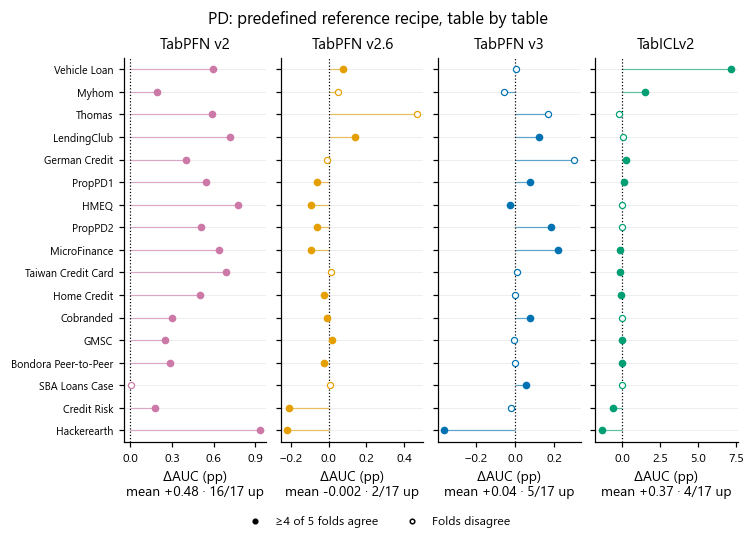

PD. Experiment 1, predefined reference recipe (all trainable weights updated, peak LR 3e-7, L2-SP λ 0.003, seed 42), final five-fold benchmark: paired change in AUC (percentage points) on every held-out credit table relative to the original model of the same base. Each axis label gives the equal-table mean and the number of tables improving by more than 0.1 pp. Filled markers: at least four of the five outer folds change in the direction of the table mean; open markers: the folds disagree. Tables are ordered by their mean effect across the four bases; horizontal axes differ between models. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. 

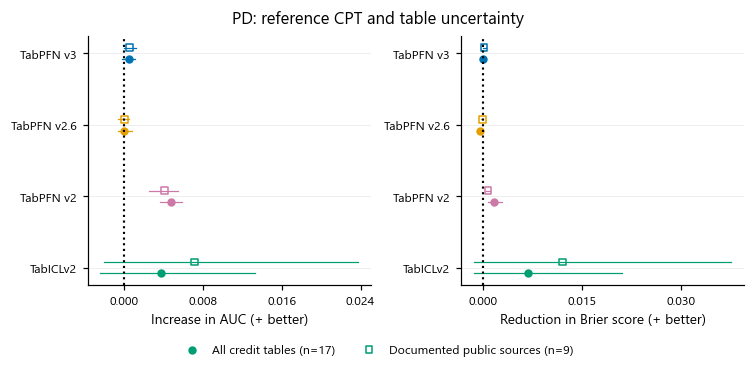

PD. Mean paired benchmark effects of the predefined full-update CPT reference and 95% conditional table-bootstrap intervals. Positive effects favor CPT; RMSE is reported as fractional error reduction. Filled circles include all credit tables; open squares retain documented public sources. Each table contributes the mean of five paired outer folds. Source restriction is based on provenance, not scores. Intervals do not capture training-seed uncertainty or establish source independence.

,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed,metric
0,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Bondora Peer-to-Peer,0.897214,0.896647,-0.000567,-0.000567,Bondora Peer-to-Peer,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.000567,42,roc_auc
1,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Cobranded,0.842771,0.842742,-0.000028,-0.000028,Cobranded,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.000028,42,roc_auc
2,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Credit Risk,0.955142,0.948972,-0.006170,-0.006170,Credit Risk,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.006170,42,roc_auc
3,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,GMSC,0.867187,0.866617,-0.000570,-0.000570,GMSC,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.000570,42,roc_auc
4,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,German Credit,0.790140,0.792556,0.002416,0.002416,German Credit,TabICLv2,3.000000e-07,False,0.003,one_sample,0.002416,42,roc_auc
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropPD2,0.229404,0.229532,0.000128,0.000128,PropPD2,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.000128,42,f1
404,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,SBA Loans Case,0.923122,0.929796,0.006675,0.006675,SBA Loans Case,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.006675,42,f1
405,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Taiwan Credit Card,0.548195,0.547957,-0.000238,-0.000238,Taiwan Credit Card,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.000238,42,f1
406,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Thomas,0.432436,0.442147,0.009711,0.009711,Thomas,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.009711,42,f1


In [5]:
endpoint = cp.reference_rows(cp.benchmark_effects(run))
cp.show(sink, sy.plot_reference_tables(effects, TRACK), track=TRACK)
cp.show(sink, finish.plot_uncertainty(run), track=TRACK)
report.table('Fixed-reference effects for every table and metric', ce.reference_profiles(run))
report.add('4. The predefined reference, table by table', cp.effect_summary(endpoint) + '\n' + finish.UNCERTAINTY_NOTE + '\n' + finish.SOURCE_NOTE)

## 5. Probability quality and prediction shifts

AUC assesses ranking, while Brier score and log loss assess predictive probabilities. The calibration overview uses the same tables for raw, Platt and isotonic scores; calibration is fitted on inner validation rows, never outer test labels. Saved predictions describe systematic over/underprediction and changes relative to original weights; these are not a theoretical bias-variance decomposition.

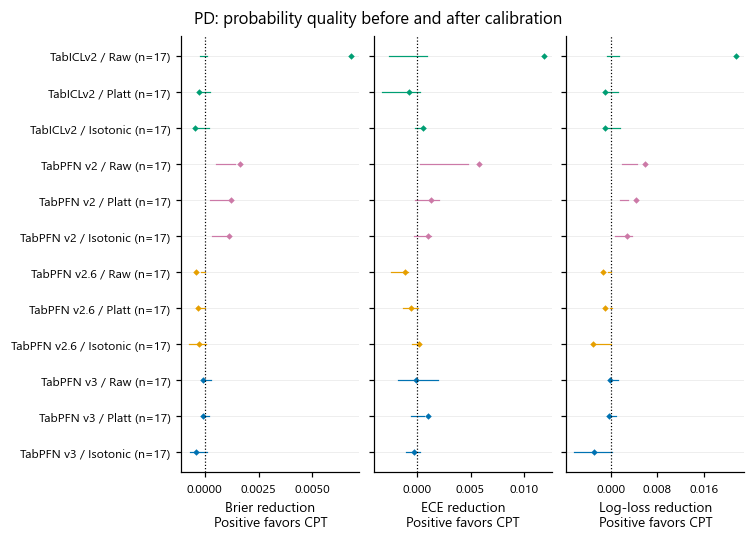

PD. Changes in the displayed outer-test probability-quality scores for the predefined full-update reference (LR 3e-7, L2-SP 0.003, one-sample training) relative to its untuned base. Positive reductions favor continued pretraining (CPT). Raw probabilities and validation-fitted Platt and isotonic calibration use a common dataset cohort within each base: all 9 scores require the same five completed, matched outer folds. Diamonds show equal-dataset means; horizontal lines span dataset quartiles, not confidence intervals. Log loss, when exported, is in nats; ECE depends on the binning scheme.

,base,dataset,partition,arm,status,reason
0,TabICLv2,Bondora Peer-to-Peer,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,HMEQ,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,MicroFinance,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,Thomas,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,GMSC,1,Reference CPT,verified,"Five folds; matched row identities, targets an..."
...,...,...,...,...,...,...
63,TabPFN v3,PropPD2,2,Reference CPT,verified,"Five folds; matched row identities, targets an..."
64,TabPFN v3,Cobranded,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."
65,TabPFN v3,Home Credit,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."
66,TabPFN v3,LendingClub,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,Bondora Peer-to-Peer,0,Reference CPT,730176,0.138105,0.135123,0.132569,-0.002982,-0.005536,-0.002554,0.080536,0.080619,-0.000083,-0.002554,0.019772,0.009558
1,TabICLv2,HMEQ,0,Reference CPT,5960,0.199497,0.190717,0.192194,-0.008779,-0.007303,0.001476,0.017686,0.018154,-0.000468,0.001476,0.034721,0.011352
2,TabICLv2,MicroFinance,0,Reference CPT,158700,0.378091,0.364956,0.364263,-0.013134,-0.013828,-0.000693,0.218164,0.218413,-0.000249,-0.000693,0.028269,0.021001
3,TabICLv2,Thomas,0,Reference CPT,1225,0.263673,0.247090,0.244012,-0.016584,-0.019662,-0.003078,0.183083,0.183146,-0.000063,-0.003078,0.014727,0.010257
4,TabICLv2,GMSC,1,Reference CPT,150000,0.066840,0.057865,0.056626,-0.008975,-0.010214,-0.001239,0.049076,0.049166,-0.000090,-0.001239,0.007366,0.003548
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63,TabPFN v3,PropPD2,2,Reference CPT,105471,0.092755,0.075083,0.077348,-0.017673,-0.015407,0.002265,0.082365,0.082222,0.000144,0.002265,0.007568,0.005367
64,TabPFN v3,Cobranded,3,Reference CPT,80000,0.246213,0.234716,0.236553,-0.011496,-0.009659,0.001837,0.130932,0.130591,0.000341,0.001837,0.017345,0.009891
65,TabPFN v3,Home Credit,3,Reference CPT,307511,0.080729,0.066750,0.068345,-0.013979,-0.012384,0.001595,0.068395,0.068366,0.000030,0.001595,0.009478,0.005742
66,TabPFN v3,LendingClub,3,Reference CPT,9578,0.160054,0.140981,0.138785,-0.019073,-0.021269,-0.002196,0.126388,0.126412,-0.000024,-0.002196,0.011739,0.008609


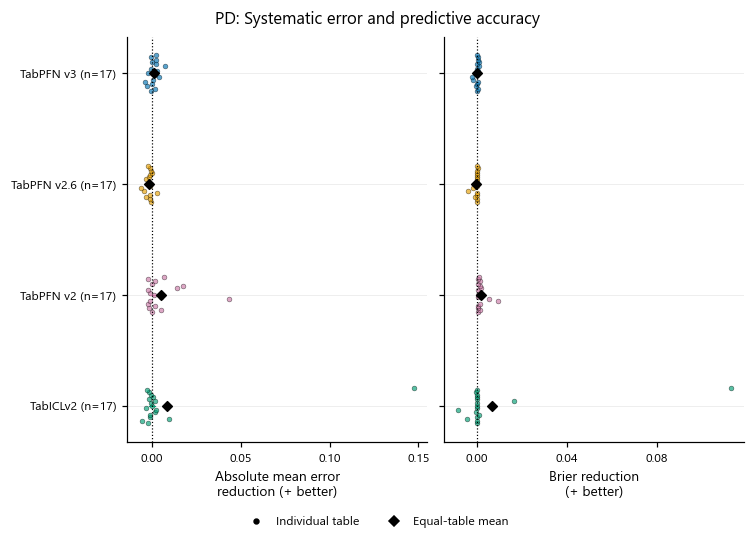

PD. Matched five-fold out-of-fold predictions on held-out credit tables. Circles show individual tables; their small vertical offsets follow table-name order and have no quantitative meaning. Black diamonds are equal-table means; segments are dataset interquartile ranges, not confidence intervals. Each label gives the number of tables. Mean error is predicted minus observed target, pooled over test rows within a table. The left panel measures reduction of its absolute value; the right measures reduction in squared error. These are empirical errors, not a theoretical bias–variance decomposition.

In [6]:
cp.show(sink, dg.plot_calibration_overview(run), track=run.track)
prediction_values, prediction_coverage = pred.analyze(run, reference=True)
report.table('Saved prediction coverage: fixed reference', prediction_coverage)
report.table('Paired per-table prediction diagnostics: fixed reference', prediction_values)
cp.show(sink, pred.plot_diagnostics(prediction_values, TRACK, coverage=prediction_coverage), track=TRACK)
report.add('5. Probability quality and prediction shifts', 'Brier score combines discrimination and calibration; ECE depends on its bins. The calibration overview compares the same tables across raw, Platt and isotonic scores; threshold-dependent F1 and ranking PR-AUC are included in the fixed-reference metric table.' + '\n' + pred.NOTE)

## 6. Fixed-context monitors, controls and cost

Monitoring uses fixed contexts during training and is distinct from the final five-fold benchmark above. Plot score change against learning rate, so both axes communicate a CPT choice or its effect. Separate legend boxes define learning rate, anchoring and update scope. Classical controls contextualize predictive performance; cost remains a compact table.

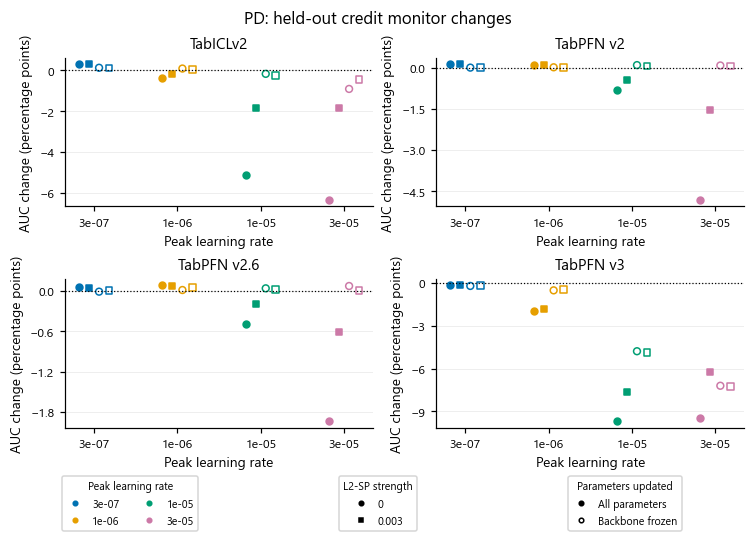

PD. Held-out credit fixed-context monitors at 10,000 successful updates, paired with update zero. 17 complete tables per model. Each mark is an equal-table mean for one rate, anchoring and update-scope combination on a recipe-complete cohort. Horizontal offsets separate the four combinations at each rate; they have no quantitative meaning. Colors encode rate, circle/square encodes L2-SP, and filled/open marks encode full/frozen-backbone updates. Zero means unchanged score. Vertical scales vary by base to expose small effects. These fixed-context monitoring measurements are separate from the final five-fold benchmark.

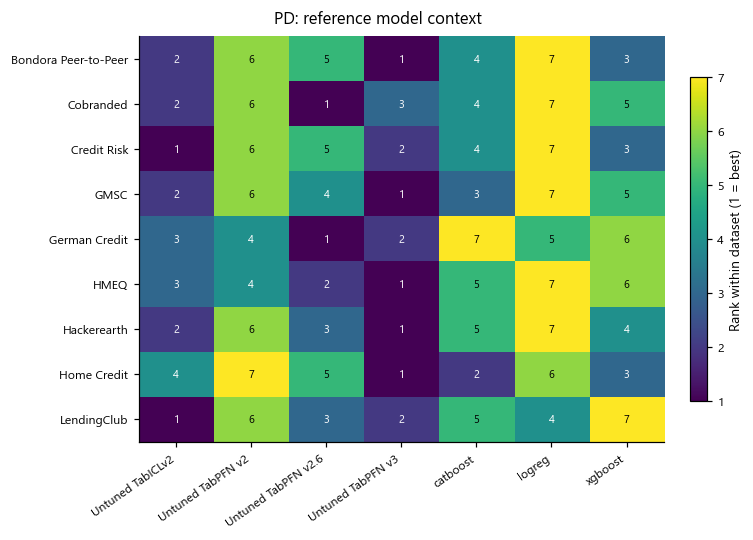

PD. Within-dataset ranks of untuned foundation models and classical controls, using complete outer-fold mean scores. Only datasets with every displayed control are included. Ranks provide corpus context; they do not quantify the size of the continued-pretraining effect.

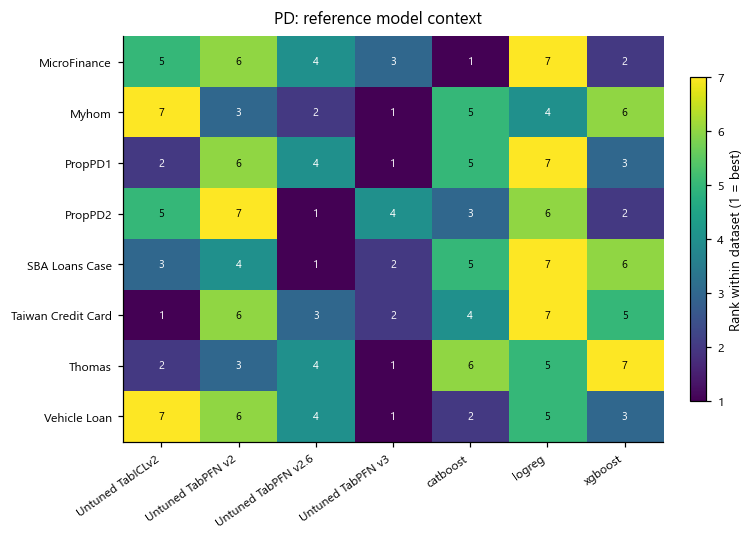

PD. Within-dataset ranks of untuned foundation models and classical controls, using complete outer-fold mean scores. Only datasets with every displayed control are included. Ranks provide corpus context; they do not quantify the size of the continued-pretraining effect.

,"('elapsed_sec', 'count')","('elapsed_sec', 'median')","('elapsed_sec', 'min')","('elapsed_sec', 'max')","('sec_per_step', 'count')","('sec_per_step', 'median')","('sec_per_step', 'min')","('sec_per_step', 'max')","('peak_gpu_gb', 'count')","('peak_gpu_gb', 'median')",...,"('rows_seen', 'min')","('rows_seen', 'max')","('trainable_params', 'count')","('trainable_params', 'median')","('trainable_params', 'min')","('trainable_params', 'max')","('final_drift', 'count')","('final_drift', 'median')","('final_drift', 'min')","('final_drift', 'max')"
"('TabICLv2', False)",32,5880.051329,5388.954923,6227.217700,32,0.588005,0.538895,0.622722,32,27.1190,...,168231937,195157151,32,27552250.0,27552250,27552250,32,0.003687,0.001127,0.028629
"('TabICLv2', True)",32,5641.459922,5191.705577,5953.787302,32,0.564146,0.519171,0.595379,32,26.7075,...,168231937,195157151,32,1818106.0,1818106,1818106,32,0.006402,0.001463,0.042363
"('TabPFN v2', False)",32,4989.562487,4558.125119,5434.754171,32,0.498956,0.455813,0.543475,32,181.0705,...,74887937,84373151,32,7244554.0,7244554,7244554,32,0.004249,0.001053,0.028788
"('TabPFN v2', True)",32,4818.276219,4399.349810,5211.900758,32,0.481828,0.439935,0.521190,32,108.1805,...,74887937,84373151,32,166666.0,166666,166666,32,0.006800,0.001252,0.078394
"('TabPFN v2.6', False)",32,4264.081141,3931.728692,4570.578204,32,0.426408,0.393173,0.457058,32,128.4200,...,80721937,91297151,32,10732042.0,10732042,10732042,32,0.003833,0.000877,0.040765
"('TabPFN v2.6', True)",32,3799.214932,3556.330243,4103.147097,32,0.379921,0.355633,0.410315,32,80.4470,...,80721937,91297151,32,101386.0,101386,101386,32,0.001670,0.000229,0.015853
"('TabPFN v3', False)",32,5222.860977,4837.436067,5610.246155,32,0.522286,0.483744,0.561025,32,121.0455,...,168231937,195157151,32,53153136.0,53153136,53153136,32,0.006299,0.001484,0.052170
"('TabPFN v3', True)",32,4818.272543,4506.762127,5040.165402,32,0.481827,0.450676,0.504017,32,109.9990,...,168231937,195157151,32,1795440.0,1795440,1795440,32,0.006421,0.001305,0.037843


In [7]:
cp.show(sink, ce.plot_monitor_changes(run), track=TRACK)
cp.show(sink, cp.plot_control_context(run), track=TRACK)
report.table('Completed-trial computational cost', pub.cost_summary(run))
report.add('6. Fixed-context monitors, controls and cost', 'Monitor changes pair each excluded credit table with its own update-zero score, then average tables equally. Monitor and final benchmark results answer related but distinct measurement questions. One main training seed and overlapping adaptation corpora limit independence claims.')

## Complete text summary

Every displayed value, table and caption, in section order. Detailed table effects remain available even where compact figures replace repeated panels.

In [8]:
print(report.summary(sink))

Experiment 1: PD outcomes and evaluation

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
Does stronger credit-domain adaptation improve transfer to excluded credit tables, and what does it preserve or lose on the non-credit panel? The grid is descriptive; the highest test score is not a selected deployment result.

1. Evidence and benchmark eligibility
Run cpt_main_v5; PD; 256 planned trials; target 10,000 successful updates.
status
OK    256
1536 trajectory records; 11715 benchmark fold records.
PENDING means no recorded outcome; it can include running or queued work. This is not live scheduler state.

Table: Available evidence
CSV (first column: row index)
row,evidence,records,origin
0,Planned trials,256,Config; not scheduler state
1,Completed trials,256,DATA manifests
2,Epoch rows,201472,Project training diagnostics
3,Milestone rows,1536,Project traj